# Tidy Pipeline — BRFSS Heart Disease

End-to-end model pipeline built on the project modules:

| module | role |
|---|---|
| `preprocessing.py` | selection, sentinel decode, split-fitted fills, NaN indicators, quantile clipping, one-hot; **`load_raw` caches the CSV parse (40s -> 0s after first call)** |
| `training.py` | `LogisticClassifier` (standard = lam 0, L2-regularised, or class-weighted via `w_pos`) |
| `diagnostics.py` | `Diagnostics.evaluate / report / cross_validate` — CV returns per-fold **scores**, so plots and threshold tuning reuse the grid run (single pass) |

Workflow: load once -> per-fold pipeline cache (model-independent) -> grid search
(one fit per fold per config) -> pooled OOF -> figures + threshold -> final fit ->
submission. No stage recomputes another stage's work.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import helpers
import preprocessing as pp
import training as tr
import diagnostics as dg
import diagstat as ds

## 1. Load data (cached)

First call parses the CSVs (~40s); every later `run_train` in this kernel
reuses the cached arrays (~1.5s). The cache is keyed on the files'
(path, size, mtime), so a changed dataset is re-read automatically.

In [2]:
import setup_data
setup_data.main()

extracting data/dataset_to_release.zip -> data/dataset/ ...
  extracted x_train.csv             227,376,867 bytes
  extracted y_train.csv               3,469,411 bytes
  extracted x_test.csv               91,705,179 bytes
  extracted sample_submission.csv     1,203,182 bytes
done. Data is ready - open run.ipynb and Run All.


0

In [2]:
data = pp.run_train(verbose=False)
y = data["y"].astype(float)
print("train:", data["x_1h"].shape, "| test raw:", data["x_test_raw"].shape)
print("positives:", f"{y.mean():.2%}")

train: (328135, 114) | test raw: (109379, 321)
positives: 8.83%


## 2. Per-fold Preprocessing 

The fills / clips / flags depend only on the fold split, not on the model
hyperparameters. Build the fold matrices once; the grid search below reads
them.

In [3]:
K = 5
folds = helpers.k_fold_split(len(y), K)

fold_cache = []
for tr_idx, va_idx in folds:
    d = pp.run_train(verbose=False, fit_idx=tr_idx)   # fills fitted on fold's train ONLY
    fold_cache.append({
        "x_tr": d["x_1h"][tr_idx].astype(float),
        "x_va": d["x_1h"][va_idx].astype(float),
        "y_tr": y[tr_idx], "y_va": y[va_idx],
        "va_idx": va_idx,
    })

def fold_data(tr_idx, va_idx):
    """Memoized hook for Diagnostics.cross_validate: serves cached matrices,
    so the per-fold preprocessing is computed once and reused by every config."""
    for f in fold_cache:
        if len(f["y_tr"]) == len(tr_idx) and f["va_idx"][0] == va_idx[0]:
            return f["x_tr"], f["x_va"]
    raise KeyError("fold not in cache")

print("fold cache:", [f["x_tr"].shape[0] for f in fold_cache], "train rows per fold")

fold cache: [262508, 262508, 262508, 262508, 262508] train rows per fold


## 3. Grid search for Best Parameter by Cross Validation

`cross_validate` fits each fold and returns metrics **plus** the fold's
predicted scores and row indices — everything the figures and the final
threshold need. Selection rule: mean F1 at the per-fold tuned threshold
(the leaderboard metric); AUC is the sanity column.

In [4]:
def make_classifier(lam, w_pos):
    """Factory: a FRESH classifier for the given config."""
    return lambda: tr.LogisticClassifier(lam=lam, w_pos=w_pos,
                                         gamma=0.1, max_iters=500)

LAMBDAS = [0, 1e-5, 1e-3]
WEIGHTS = [1.0, 5.0]

all_results = {}
for lam in LAMBDAS:
    for w_pos in WEIGHTS:
        all_results[(lam, w_pos)] = dg.Diagnostics.cross_validate(
            None, y, make_classifier(lam, w_pos), k=K,
            metrics=["f1", "precision", "recall", "auc"],
            verbose=False, fold_preprocess=fold_data)

print(f"{'lam':>8} {'w_pos':>6} {'F1':>8} {'±':>7} {'AUC':>8}")
for (lam, w_pos), res in all_results.items():
    f1 = np.mean([r["f1"] for r in res]); f1s = np.std([r["f1"] for r in res])
    auc = np.mean([r["auc"] for r in res])
    print(f"{lam:>8.0e} {w_pos:>6g} {f1:>8.4f} {f1s:>7.4f} {auc:>8.4f}")

best_key = max(all_results,
               key=lambda k: np.mean([r["f1"] for r in all_results[k]]))
print(f"\nbest config: lam={best_key[0]:.0e}, w_pos={best_key[1]:g}")

     lam  w_pos       F1       ±      AUC
   0e+00      1   0.4198  0.0031   0.8562
   0e+00      5   0.4209  0.0030   0.8569
   1e-05      1   0.4198  0.0031   0.8562
   1e-05      5   0.4209  0.0029   0.8569
   1e-03      1   0.4200  0.0026   0.8561
   1e-03      5   0.4213  0.0028   0.8569

best config: lam=1e-03, w_pos=5


## 4. Pooled out-of-fold scores, threshold, final model

Pooled OOF: every respondent scored by the fold model that never trained on
them. Rebuilt from the grid run's returned scores — **zero refits**.

In [5]:
def oof_from_folds(fold_results, n):
    """Pooled out-of-fold scores from cross_validate's returned per-fold
    scores and row indices — no refitting."""
    p = np.zeros(n)
    for r in fold_results:
        p[r["val_idx"]] = r["scores"]
    return p

oof = {key: oof_from_folds(res, len(y)) for key, res in all_results.items()}

# threshold on the BEST config's pooled OOF, fine grid
THS = np.linspace(0.02, 0.98, 193)
f1_curve = [dg.Diagnostics.evaluate(y, oof[best_key], metrics=["f1"],
                                    threshold=t)["f1"] for t in THS]
t_star = THS[int(np.argmax(f1_curve))]
print(f"t* (pooled OOF) = {t_star:.3f}   OOF F1 = {max(f1_curve):.4f}")

# final model on ALL rows (fit_idx=None: fills on everything - deployment model)
clf_final = tr.LogisticClassifier(lam=best_key[0], w_pos=best_key[1],
                                  gamma=0.1, max_iters=1000)
clf_final.fit(data["x_1h"].astype(float), y)
print("final fit: loss", round(clf_final.result_.loss, 4))

t* (pooled OOF) = 0.550   OOF F1 = 0.4213
final fit: loss 0.3384


## 5. Report figures and stats

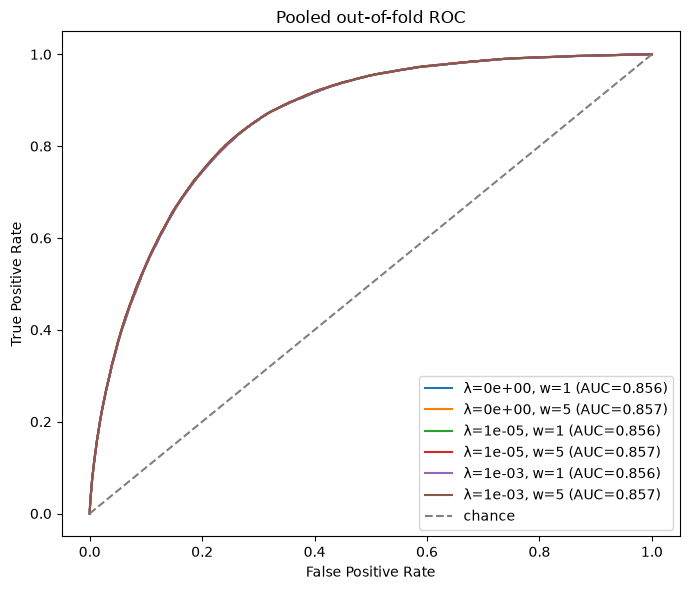

In [6]:
# --- 5a. pooled ROC, one curve per config ---
plt.figure(figsize=(7, 6))
for (lam, w_pos), p in oof.items():
    fpr, tpr, auc = ds.ROC_AUC(y, p)
    plt.plot(fpr, tpr, label=f"λ={lam:.0e}, w={w_pos:g} (AUC={auc:.3f})")
plt.plot([0, 1], [0, 1], color="grey", linestyle="--", label="chance")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("Pooled out-of-fold ROC")
plt.legend(); plt.tight_layout(); plt.show()

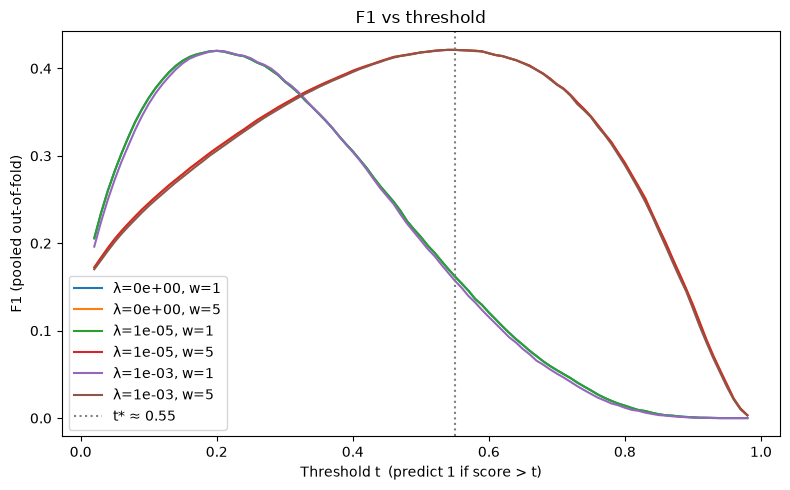

In [7]:
# --- 5b. F1 vs threshold, one curve per config ---
THS_PLOT = np.linspace(0.02, 0.98, 97)
f1_curves = {key: np.array([dg.Diagnostics.evaluate(y, p, metrics=["f1"],
                             threshold=t)["f1"] for t in THS_PLOT])
             for key, p in oof.items()}          # compute once, reuse in 5d

plt.figure(figsize=(8, 5))
for key, curve in f1_curves.items():
    plt.plot(THS_PLOT, curve, label=f"λ={key[0]:.0e}, w={key[1]:g}")
plt.axvline(t_star, color="grey", linestyle=":", label=f"t* ≈ {t_star:.2f}")
plt.xlabel("Threshold t  (predict 1 if score > t)")
plt.ylabel("F1 (pooled out-of-fold)")
plt.title("F1 vs threshold")
plt.legend(); plt.tight_layout(); plt.show()

### Per-weight panels (one subplot per class weight, one curve per lambda)

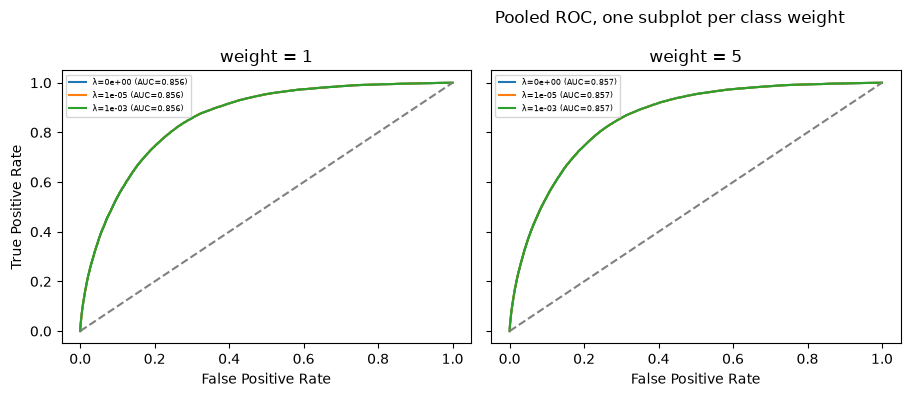

In [8]:
# --- 5c. ROC, per-weight subplots ---
weights_present = sorted({k[1] for k in oof}, key=float)
n_w = len(weights_present)
ncols = 3
nrows = int(np.ceil(n_w / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(4.5 * ncols, 4.0 * nrows),
                         sharex=True, sharey=True)
axes = np.atleast_1d(axes).ravel()
for ax, w_val in zip(axes, weights_present):
    for (lam, w_pos), p in oof.items():
        if w_pos != w_val:
            continue
        fpr, tpr, auc = ds.ROC_AUC(y, p)
        ax.plot(fpr, tpr, label=f"λ={lam:.0e} (AUC={auc:.3f})")
    ax.plot([0, 1], [0, 1], color="grey", linestyle="--")
    ax.set_title(f"weight = {w_val:g}")
    ax.set_xlabel("False Positive Rate")
    ax.legend(fontsize=6)
axes[0].set_ylabel("True Positive Rate")
for ax in axes[n_w:]:
    ax.set_visible(False)
fig.suptitle("Pooled ROC, one subplot per class weight")
fig.tight_layout(); plt.show()

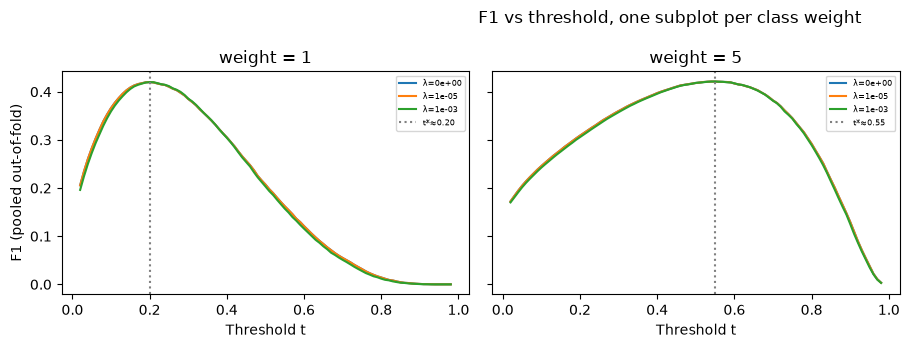

In [9]:
# --- 5d. F1 vs threshold, per-weight subplots (reuses f1_curves) ---
fig, axes = plt.subplots(nrows, ncols, figsize=(4.5 * ncols, 3.5 * nrows),
                         sharex=True, sharey=True)
axes = np.atleast_1d(axes).ravel()
for ax, w_val in zip(axes, weights_present):
    best_t, best_f1 = 0.5, -1.0
    for key, curve in f1_curves.items():
        if key[1] != w_val:
            continue
        ax.plot(THS_PLOT, curve, label=f"λ={key[0]:.0e}")
        i = int(np.argmax(curve))
        if curve[i] > best_f1:
            best_t, best_f1 = THS_PLOT[i], curve[i]
    ax.axvline(best_t, color="grey", linestyle=":", label=f"t*≈{best_t:.2f}")
    ax.set_title(f"weight = {w_val:g}")
    ax.set_xlabel("Threshold t")
    ax.legend(fontsize=6)
axes[0].set_ylabel("F1 (pooled out-of-fold)")
for ax in axes[n_w:]:
    ax.set_visible(False)
fig.suptitle("F1 vs threshold, one subplot per class weight")
fig.tight_layout(); plt.show()

In [10]:
def permutation_importance(fold_cache, factory, col_groups, n_repeats=5, seed=0):
    """AUC drop when a group of columns is row-shuffled, averaged over folds.

    Reuses the cached fold matrices; fits one model per fold (the tidy
    pipeline does not keep the grid's fitted classifiers). Delta trick:
    for a linear model, shuffling a column only changes the logit by
    w_j*(x_perm - x), so each shuffle is an O(n) update, not a matmul.
    """
    per_fold = {name: [] for name in col_groups}
    base_aucs = []
    for k, f in enumerate(fold_cache):
        clf = factory()
        clf.fit(f["x_tr"], f["y_tr"])
        x_va = (f["x_va"] - clf.result_.mu) / clf.result_.sd   # this fold's scaler
        w = clf.result_.w
        z_base = x_va @ w[1:] + w[0]
        contrib = x_va * w[1:]                                  # per-column logits
        base_auc = ds.ROC_AUC(f["y_va"], tr.sigmoid(z_base))[2]
        base_aucs.append(base_auc)
        rng = np.random.default_rng(seed + k)
        n = len(f["y_va"])
        for name, cols in col_groups.items():
            cols = np.asarray(cols, dtype=int)
            drops = []
            for _ in range(n_repeats):
                perm = rng.permutation(n)
                delta = contrib[perm][:, cols].sum(axis=1) - contrib[:, cols].sum(axis=1)
                drops.append(base_auc - ds.ROC_AUC(f["y_va"],
                            tr.sigmoid(z_base + delta))[2])
            per_fold[name].append(float(np.mean(drops)))
    agg = {name: (float(np.mean(v)), float(np.std(v)))
            for name, v in per_fold.items()}
    return agg, float(np.mean(base_aucs))


def family_indices(families, headers_1h):
    """Families -> column indices in the one-hot matrix. Matches a variable
    and its one-hot dummies (name_level) but NOT its _isnan flag — the
    missingness indicators are analysed as their own group."""
    hs = [str(h) for h in headers_1h]
    out = {}
    for fam, names in families.items():
        cols = [j for j, h in enumerate(hs)
                if any(h == nm or (h.startswith(nm + "_") and not h.endswith("_isnan"))
                        for nm in names)]
        assert cols, f"family {fam!r} matched no column"
        out[fam] = cols
    flags = [j for j, h in enumerate(hs) if h.endswith("_isnan")]
    if flags:
        out["nan_flags"] = flags
    return out


FAMILIES = {
    "general_health": ["_RFHLTH", "GENHLTH"],
    "conditions":     ["_RFHYPE5", "_RFCHOL", "_CHOLCHK", "_ASTHMS1", "CVDSTRK3",
                        "DIABETE3", "CHCCOPD1", "CHCKIDNY", "CHCSCNCR", "CHCOCNCR",
                        "HAVARTH3"],
    "demographics":   ["_AGE80", "_RACE", "_EDUCAG", "_INCOMG", "_CHLDCNT",
                        "SEX", "EMPLOY1", "MARITAL"],
    "body":           ["HTM4", "WTKG3", "_BMI5"],
    "smoking":        ["_SMOKER3"],
    "alcohol":        ["DROCDY3_", "_DRNKWEK", "_RFBING5", "_RFDRHV5"],
    "diet":           ["_FRUTSUM", "_VEGESUM"],
    "activity":       ["_TOTINDA", "ACTIN11_", "PADUR1_", "PAFREQ1_", "STRFREQ_",
                        "PAMIN11_", "PAVIG11_", "_PACAT1", "FC60_"],
    "limitation":     ["_LMTACT1", "_LMTWRK1", "_LMTSCL1", "DIFFWALK",
                        "USEEQUIP", "BLIND", "QLACTLM2", "DECIDE"],
    "prevention":     ["_RFSEAT2", "_RFSEAT3", "_PNEUMO2"],
}

factory_best = make_classifier(*best_key)

# --- family-level (the headline table) ---
fam_idx = family_indices(FAMILIES, data["headers_1h"])
agg_fam, base_auc = permutation_importance(fold_cache, factory_best, fam_idx)

print(f"base AUC = {base_auc:.4f}")
print(f"{'family':<18}{'AUC drop':>10}{'std':>8}")
for name, (m, s) in sorted(agg_fam.items(), key=lambda kv: -abs(kv[1][0])):
    print(f"{name:<18}{m:>+10.4f}{s:>8.4f}")

# --- single-column (the detail view; ~1-2 min) ---
single = {str(h): [j] for j, h in enumerate(data["headers_1h"])}
agg_col, _ = permutation_importance(fold_cache, factory_best, single)

print(f"\ntop single columns (of {len(single)}):")
for name, (m, s) in sorted(agg_col.items(), key=lambda kv: -abs(kv[1][0]))[:15]:
    print(f"  {name:<18}{m:>+8.4f}")

base AUC = 0.8569
family              AUC drop     std
conditions           +0.0708  0.0008
demographics         +0.0347  0.0012
general_health       +0.0226  0.0006
activity             +0.0125  0.0004
limitation           +0.0025  0.0002
smoking              +0.0016  0.0001
nan_flags            +0.0009  0.0002
prevention           +0.0007  0.0002
alcohol              +0.0006  0.0001
body                 -0.0000  0.0000
diet                 -0.0000  0.0000

top single columns (of 114):
  SEX                +0.0190
  GENHLTH            +0.0160
  FC60_              +0.0121
  _RFCHOL            +0.0096
  _RFHYPE5           +0.0084
  CVDSTRK3           +0.0073
  _AGE80             +0.0056
  CHCCOPD1           +0.0031
  _SMOKER3           +0.0016
  CHCKIDNY           +0.0012
  _PNEUMO2_isnan     +0.0009
  _RFHLTH            +0.0006
  _PNEUMO2           +0.0005
  QLACTLM2           +0.0005
  DIABETE3_1.0       +0.0004


## 6. Test predictions and submission

The test pipeline consumes only TRAIN statistics (fills, clips, flag set,
one-hot levels). Predictions use the final full-train model and the OOF-tuned
threshold.

In [11]:
x_te = pp.run_test(data)                     # train's fills/clips/flags/levels
p_test = clf_final.predict_scores(x_te)
y_pred = 2 * (p_test > t_star).astype(int) - 1    # {0,1} -> {-1,+1}

assert y_pred.mean() < 0, "sign check: ~11% flagged -> mean ~ -0.77"
print(f"flagged {100 * (y_pred == 1).mean():.1f}% of test rows as positive")

helpers.create_csv_submission(data["test_ids"], y_pred, "submission.csv")
print("wrote submission.csv")

flagged 14.1% of test rows as positive
wrote submission.csv
